# Network Intrusion Detection on UNSW-NB15

Classifying network flows as **normal** or one of nine **attack categories** using classical machine learning.

**Dataset:** UNSW-NB15 (Moustafa & Slay, UNSW Canberra). Each row is one network flow described by 42 features (duration, byte/packet counts, TTLs, TCP window sizes, connection-tracking counts, ...). The notebook uses the **official partitions**: `UNSW_NB15_training-set.csv` (175,341 flows) to train and `UNSW_NB15_testing-set.csv` (82,332 flows) to test.

**Two tasks**
1. **Binary:** `label` (0 = normal, 1 = attack)
2. **Multiclass:** `attack_cat` (Normal, Generic, Exploits, Fuzzers, DoS, Reconnaissance, Analysis, Backdoor, Shellcode, Worms)

**Approach**
- Train on the official training file, evaluate on the official testing file. The test file is never used for fitting or preprocessing.
- Remove duplicate flows from the training data, so repeated flows are not over-weighted.
- Fit every transformation (scaling, encoding, log transform) inside scikit-learn `Pipeline`s on the training data only.
- Compare a majority-class baseline, logistic regression, random forest and gradient boosting.
- Report **macro-F1** and the **false-alarm rate**, not just accuracy.
- Diagnose the gap between in-distribution and official-test performance (section 9).

**To run:** place both CSV files in `data/`, then run all cells.

## 1. Setup

In [ ]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from joblib import parallel_backend

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, classification_report, confusion_matrix,
                             f1_score, accuracy_score, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 50)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

Random_State = 42
Train_Path = Path("data/UNSW_NB15_training-set.csv")
Test_Path = Path("data/UNSW_NB15_testing-set.csv")
Model_Dir = Path("models")

Cat_Cols = ["proto", "service", "state"]
Targets = ["label", "attack_cat"]

## 2. Load and inspect the data

In [ ]:
def load(path):
    """Read a UNSW-NB15 CSV and apply the SAME cleaning to train and test."""
    df = pd.read_csv(path).drop(columns=["id"])
    num = [c for c in df.columns if c not in Cat_Cols + Targets]
    df[num] = df[num].apply(pd.to_numeric, errors="coerce").fillna(0)
    return df

train_raw, test_raw = load(Train_Path), load(Test_Path)
assert set(train_raw.columns) == set(test_raw.columns), "train/test columns differ"

Num_Cols = [c for c in train_raw.columns if c not in Cat_Cols + Targets]
print(f"Train: {len(train_raw):,} rows   Test: {len(test_raw):,} rows   Numeric features: {len(Num_Cols)}")
print("Missing values (train/test):", int(train_raw.isna().sum().sum()), "/", int(test_raw.isna().sum().sum()))
train_raw.head()

Train: 175,341 rows   Test: 82,332 rows   Numeric features: 39
Missing values (train/test): 0 / 0


,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sttl,dttl,sload,dload,sloss,dloss,sinpkt,dinpkt,sjit,djit,swin,stcpb,dtcpb,dwin,tcprtt,synack,ackdat,smean,dmean,trans_depth,response_body_len,ct_srv_src,ct_state_ttl,ct_dst_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,0.121478,tcp,-,FIN,6,4,258,172,74.087490,252,254,14158.942380,8495.365234,0,0,24.295600,8.375000,30.177547,11.830604,255,621772692,2202533631,255,0.000000,0.000000,0.000000,43,43,0,0,1,0,1,1,1,1,0,0,0,1,1,0,Normal,0
1,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,62,252,8395.112305,503571.312500,2,17,49.915000,15.432865,61.426934,1387.778330,255,1417884146,3077387971,255,0.000000,0.000000,0.000000,52,1106,0,0,43,1,1,1,1,2,0,0,0,1,6,0,Normal,0
2,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,62,252,1572.271851,60929.230470,1,6,231.875571,102.737203,17179.586860,11420.926230,255,2116150707,2963114973,255,0.111897,0.061458,0.050439,46,824,0,0,7,1,2,1,1,3,0,0,0,2,6,0,Normal,0
3,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,62,252,2740.178955,3358.622070,1,3,152.876547,90.235726,259.080172,4991.784669,255,1107119177,1047442890,255,0.000000,0.000000,0.000000,52,64,0,0,1,1,2,1,1,3,1,1,0,2,1,0,Normal,0
4,0.449454,tcp,-,FIN,10,6,534,268,33.373826,254,252,8561.499023,3987.059814,2,1,47.750333,75.659602,2415.837634,115.807000,255,2436137549,1977154190,255,0.128381,0.071147,0.057234,53,45,0,0,43,1,2,2,1,40,0,0,0,2,39,0,Normal,0


### 2.1 Duplicate flows

Once the row `id` is removed, many flows turn out to be identical. In the **training** data I drop them so that repeated flows do not dominate what the model learns.

The **official test set is left exactly as shipped**, so the numbers stay comparable with other work on this benchmark. Because duplicates in the test set can sway the scores, I also report results on a de-duplicated copy as a sensitivity check (section 6.2).

In [ ]:
for name, d in [("train", train_raw), ("test", test_raw)]:
    n_dup = d.duplicated().sum()
    print(f"{name}: {n_dup:,} duplicate rows ({n_dup / len(d):.1%})")

train = train_raw.drop_duplicates().reset_index(drop=True)
test = test_raw.copy()
test_dedup = test_raw.drop_duplicates().reset_index(drop=True)
print(f"\nTrain after de-duplication: {len(train):,}   Test (as shipped): {len(test):,}   Test (de-duplicated): {len(test_dedup):,}")

train: 67,601 duplicate rows (38.6%)
test: 26,387 duplicate rows (32.0%)

Train after de-duplication: 107,740   Test (as shipped): 82,332   Test (de-duplicated): 55,945


### 2.2 Target distribution: train vs test

The two partitions were built differently, so first check whether their class mixes match.

label and attack_cat are consistent in both files


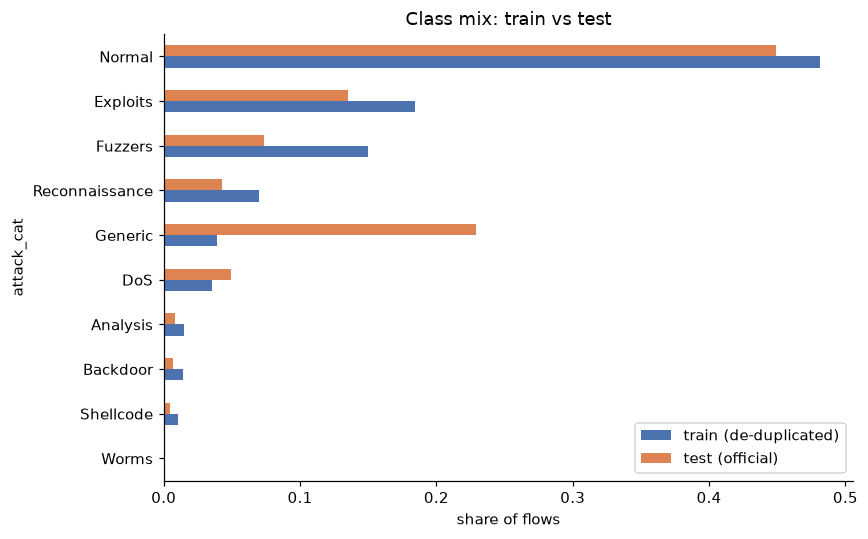

                train (de-duplicated)  test (official)
attack_cat                                            
Worms                             0.1              0.1
Shellcode                         1.0              0.5
Backdoor                          1.4              0.7
Analysis                          1.5              0.8
DoS                               3.5              5.0
Generic                           3.9             22.9
Reconnaissance                    7.0              4.2
Fuzzers                          15.0              7.4
Exploits                         18.4             13.5
Normal                           48.2             44.9


In [ ]:
for name, d in [("train", train), ("test", test)]:
    assert (d["label"] == (d["attack_cat"] != "Normal").astype(int)).all(), f"{name}: label/attack_cat disagree"
print("label and attack_cat are consistent in both files")

dist = pd.DataFrame({
    "train (de-duplicated)": train["attack_cat"].value_counts(normalize=True),
    "test (official)": test["attack_cat"].value_counts(normalize=True),
}).fillna(0).sort_values("train (de-duplicated)")

ax = dist.plot.barh(figsize=(8, 5), color=["#4C72B0", "#DD8452"])
ax.set_xlabel("share of flows"); ax.set_title("Class mix: train vs test")
plt.tight_layout(); plt.show()
print((dist * 100).round(1).to_string())

The class mix differs noticeably between the partitions (compare Generic, for example). A model is therefore evaluated under **distribution shift**, which is closer to deployment than a random split but also lower-scoring. Plain accuracy would also hide poor performance on the rare classes, so **macro-F1** (the unweighted mean of per-class F1) is the headline metric for the multiclass task.

### 2.3 Categorical features

proto      133
service     13
state        9

Categories in test but not in train: {'proto': [], 'service': [], 'state': ['ACC', 'CLO']}


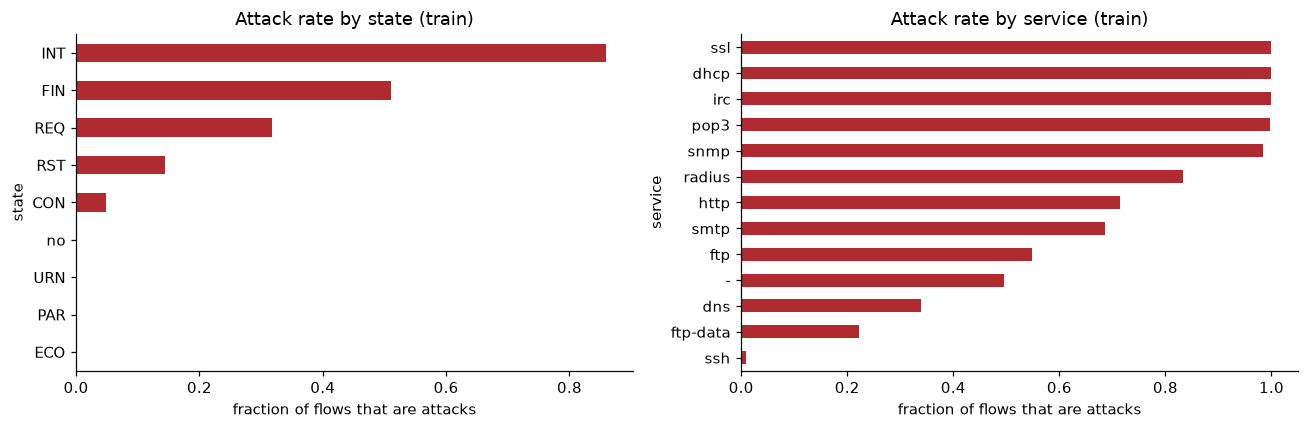

In [ ]:
print(train[Cat_Cols].nunique().rename("n_unique (train)").to_string())
unseen = {c: sorted(set(test[c]) - set(train[c])) for c in Cat_Cols}
print("\nCategories in test but not in train:", unseen)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ["state", "service"]):
    train.groupby(col)["label"].mean().sort_values().plot.barh(ax=ax, color="#B02B2F")
    ax.set_title(f"Attack rate by {col} (train)")
    ax.set_xlabel("fraction of flows that are attacks")
plt.tight_layout(); plt.show()

### 2.4 Skewed numeric features

Byte counts, rates, durations and loads span many orders of magnitude. Linear models handle this badly, so I apply `log1p` to strongly skewed, non-negative columns (chosen from the training data only). Tree models are unaffected by monotonic transforms, so they will not need it.

trans_depth          136.4
response_body_len     60.3
sbytes                35.6
sloss                 35.2
dloss                 33.6
dbytes                32.1
spkts                 32.0
dpkts                 30.0
dinpkt                30.0
djit                  26.9


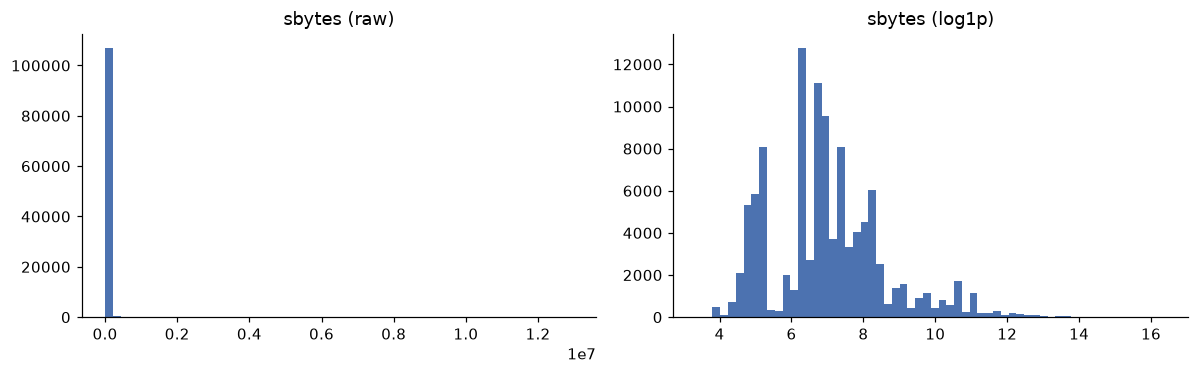

In [ ]:
skew = train[Num_Cols].skew().sort_values(ascending=False)
print(skew.head(10).round(1).to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(train["sbytes"], bins=60, color="#4C72B0");          axes[0].set_title("sbytes (raw)")
axes[1].hist(np.log1p(train["sbytes"]), bins=60, color="#4C72B0"); axes[1].set_title("sbytes (log1p)")
plt.tight_layout(); plt.show()

## 3. Train / test inputs

The official partitions are used as they are, so there is no `train_test_split` here.

In [ ]:
X_train, X_test = train.drop(columns=Targets), test.drop(columns=Targets)
ym_train, ym_test = train["attack_cat"], test["attack_cat"]
yb_train, yb_test = train["label"], test["label"]

assert list(X_train.columns) == list(X_test.columns)
assert set(ym_test) <= set(ym_train), "test contains classes never seen in training"
print(f"Train: {len(X_train):,}   Test: {len(X_test):,}   Features: {X_train.shape[1]}")

Train: 107,740   Test: 82,332   Features: 42


## 4. Preprocessing pipelines

Everything is fitted **inside a pipeline on the training data only**.

- **Linear model:** `log1p` on skewed numeric columns, standard scaling, one-hot encoding of categoricals.
- **Tree models:** one-hot encoding of categoricals, numeric columns passed through unchanged.
- `proto` has over 100 distinct values, many of them very rare, so infrequent categories are grouped into one bucket. Categories that only appear at test time are handled the same way.
- Low-cardinality count columns (`ct_state_ttl`, `ct_ftp_cmd`, `is_ftp_login`) stay numeric.

In [ ]:
skew_train = X_train[Num_Cols].skew()
LOG_COLS = [c for c in Num_Cols if skew_train[c] > 5 and X_train[c].min() >= 0]
LINEAR_NUM_COLS = [c for c in Num_Cols if c not in LOG_COLS]
print(f"{len(LOG_COLS)} columns log-transformed:", LOG_COLS)

def make_ohe():
    return OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.005,
                         sparse_output=False)

def linear_preprocessor():
    return ColumnTransformer([
        ("log", Pipeline([("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                          ("scale", StandardScaler())]), LOG_COLS),
        ("num", StandardScaler(), LINEAR_NUM_COLS),
        ("cat", make_ohe(), Cat_Cols),
    ])

def tree_preprocessor():
    return ColumnTransformer([
        ("num", "passthrough", Num_Cols),
        ("cat", make_ohe(), Cat_Cols),
    ])

22 columns log-transformed: ['dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'synack', 'trans_depth', 'response_body_len', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'is_sm_ips_ports']


## 5. Models

A majority-class **dummy baseline** is included so that every other score has a reference point. Note that after de-duplication the training data is roughly half attack, so the *binary* dummy predicts "attack" for everything; that is why it gets perfect recall and a non-zero F1. Class weights are set to `balanced` where supported, so the rare attack types are not ignored.

In [ ]:
def build_models():
    return {
        "Dummy (majority)": Pipeline([("pre", tree_preprocessor()),
                                      ("clf", DummyClassifier(strategy="most_frequent"))]),
        "Logistic Regression": Pipeline([("pre", linear_preprocessor()),
                                         ("clf", LogisticRegression(max_iter=1000, class_weight="balanced"))]),
        "Random Forest": Pipeline([("pre", tree_preprocessor()),
                                   ("clf", RandomForestClassifier(n_estimators=200, n_jobs=-1,
                                                                  class_weight="balanced_subsample",
                                                                  Random_State=Random_State))]),
        "Gradient Boosting": Pipeline([("pre", tree_preprocessor()),
                                       ("clf", HistGradientBoostingClassifier(class_weight="balanced",
                                                                              Random_State=Random_State))]),
    }

## 6. Task 1: binary classification (normal vs attack)

In [ ]:
def binary_scores(model, X, y):
    pred = model.predict(X)
    proba = model.predict_proba(X)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    return {
        "accuracy": accuracy_score(y, pred),
        "precision": precision_score(y, pred, zero_division=0),
        "recall": recall_score(y, pred),
        "f1": f1_score(y, pred),
        "roc_auc": roc_auc_score(y, proba),
        "false_alarm_rate": fp / (fp + tn),
    }

bin_models = build_models()
for model in bin_models.values():
    model.fit(X_train, yb_train)

bin_results = pd.DataFrame({n: binary_scores(m, X_test, yb_test) for n, m in bin_models.items()}).T.round(4)
bin_results.index.name = "model"
bin_results

,accuracy,precision,recall,f1,roc_auc,false_alarm_rate
model,,,,,,
Dummy (majority),0.5506,0.5506,1.0000,0.7102,0.5000,1.0000
Logistic Regression,0.8181,0.7617,0.9746,0.8551,0.9575,0.3736
Random Forest,0.8716,0.8187,0.9848,0.8941,0.9804,0.2671
Gradient Boosting,0.8793,0.8274,0.9866,0.9000,0.9866,0.2522


For intrusion detection, **recall** (how many attacks are caught) and **precision** (how many alerts are real) pull in opposite directions. The **false-alarm rate** makes the cost concrete: the share of normal traffic that gets flagged. Compare precision, recall and false-alarm rate together; a high recall with a high false-alarm rate means the detector is catching attacks by over-alerting.

### 6.1 Binary results on the de-duplicated test set (sensitivity check)

In [ ]:
bin_results_dedup = pd.DataFrame({
    n: binary_scores(m, test_dedup.drop(columns=Targets), test_dedup["label"])
    for n, m in bin_models.items()}).T.round(4)
bin_results_dedup.index.name = "model"
bin_results_dedup

,accuracy,precision,recall,f1,roc_auc,false_alarm_rate
model,,,,,,
Dummy (majority),0.3886,0.3886,1.0000,0.5597,0.5000,1.0000
Logistic Regression,0.7559,0.6209,0.9545,0.7524,0.9250,0.3703
Random Forest,0.8304,0.7035,0.9741,0.8170,0.9656,0.2609
Gradient Boosting,0.8418,0.7183,0.9753,0.8273,0.9758,0.2431


## 7. Task 2: multiclass attack-type classification

In [12]:
def multi_scores(y, pred):
    return {"accuracy": accuracy_score(y, pred),
            "macro_f1": f1_score(y, pred, average="macro"),
            "weighted_f1": f1_score(y, pred, average="weighted")}

multi_models = build_models()
for model in multi_models.values():
    model.fit(X_train, ym_train)

multi_results = pd.DataFrame({n: multi_scores(ym_test, m.predict(X_test))
                              for n, m in multi_models.items()}).T.round(4)
multi_results.index.name = "model"
multi_results

,accuracy,macro_f1,weighted_f1
model,,,
Dummy (majority),0.4494,0.0620,0.2787
Logistic Regression,0.6139,0.3473,0.6798
Random Forest,0.7484,0.5126,0.7819
Gradient Boosting,0.6645,0.4849,0.7215


In [ ]:
# Same models, de-duplicated test set (sensitivity check)
Xd, yd = test_dedup.drop(columns=Targets), test_dedup["attack_cat"]
pd.DataFrame({n: multi_scores(yd, m.predict(Xd)) for n, m in multi_models.items()}).T.round(4)

,accuracy,macro_f1,weighted_f1
Dummy (majority),0.6114,0.0759,0.4640
Logistic Regression,0.5821,0.3697,0.6571
Random Forest,0.7553,0.5442,0.7836
Gradient Boosting,0.6416,0.5122,0.7017


**A note on model selection.** The model below is the one with the best macro-F1 *on the test set*, which is fine for diagnosing errors but makes its headline score slightly optimistic. A stricter protocol would choose between models using cross-validation on the training data and touch the test set once at the end.

In [14]:
best_name = multi_results["macro_f1"].idxmax()
best_model = multi_models[best_name]
best_pred = best_model.predict(X_test)
print(f"Best multiclass model by macro-F1: {best_name}\n")
print(classification_report(ym_test, best_pred, zero_division=0))

Best multiclass model by macro-F1: Random Forest

                precision    recall  f1-score   support

      Analysis       0.07      0.33      0.12       677
      Backdoor       0.05      0.46      0.09       583
           DoS       0.73      0.09      0.16      4089
      Exploits       0.74      0.67      0.71     11132
       Fuzzers       0.30      0.56      0.39      6062
       Generic       1.00      0.97      0.98     18871
        Normal       0.96      0.77      0.85     37000
Reconnaissance       0.94      0.80      0.86      3496
     Shellcode       0.35      0.69      0.47       378
         Worms       0.68      0.39      0.49        44

      accuracy                           0.75     82332
     macro avg       0.58      0.57      0.51     82332
  weighted avg       0.86      0.75      0.78     82332



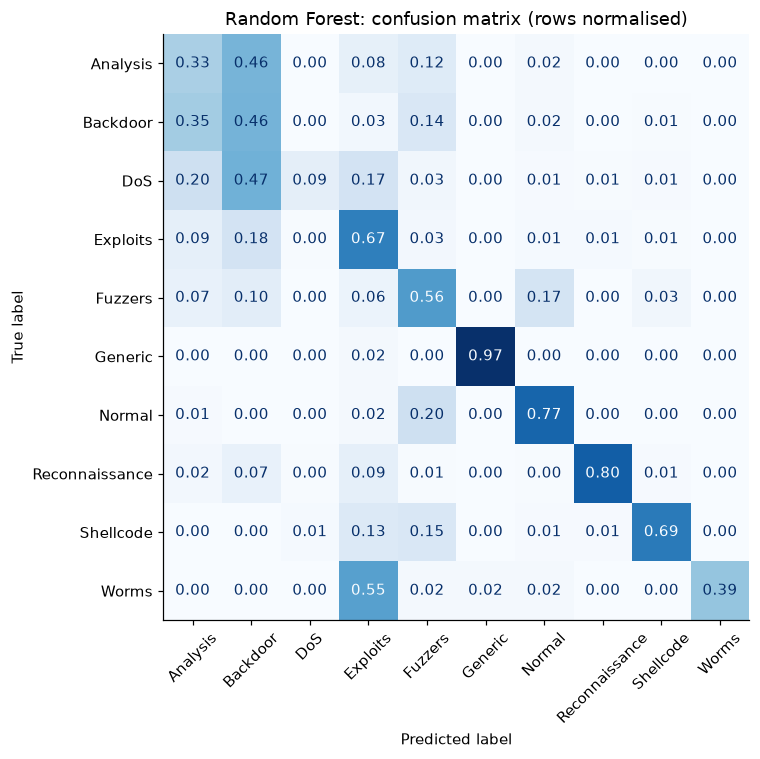

In [15]:
fig, ax = plt.subplots(figsize=(8.5, 7))
ConfusionMatrixDisplay.from_predictions(
    ym_test, best_pred, normalize="true", xticks_rotation=45,
    values_format=".2f", cmap="Blues", colorbar=False, ax=ax)
ax.set_title(f"{best_name}: confusion matrix (rows normalised)")
plt.tight_layout(); plt.show()

**Reading the matrix:** the diagonal is per-class recall. Check the **Normal** row first (how much benign traffic is being flagged?), then which rare attack categories are absorbed into larger, similar-looking ones.

## 8. Which features matter?

Permutation importance on the test set: how much does macro-F1 drop when a single raw feature is shuffled? It is computed on the full pipeline, so one-hot columns are grouped back into their original feature.

`n_jobs=1` is used on purpose. With `n_jobs=-1` joblib copies the fitted model to disk to share it with worker processes, and a random forest of 200 deep trees is large enough to fill a nearly-full temp drive (`OSError: No space left on device`, reported by joblib as a `PicklingError`). Running in a single process, or with threads, avoids the copy.

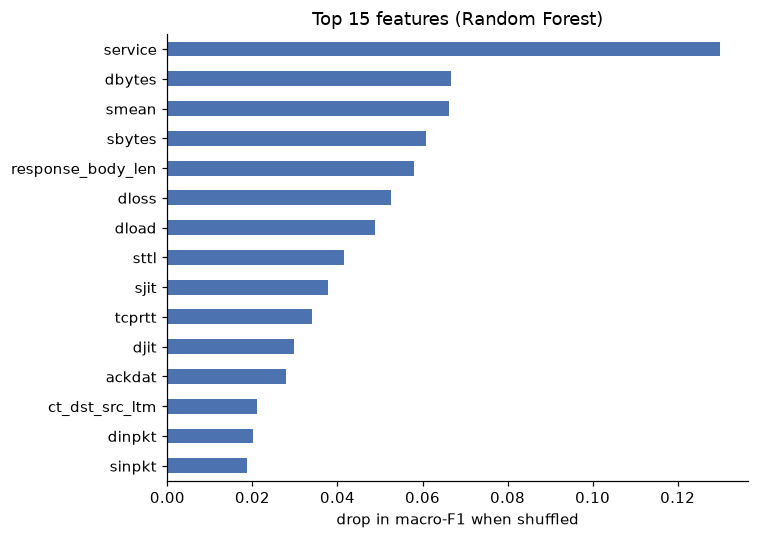

In [ ]:
sample = X_test.sample(n=min(5000, len(X_test)), Random_State=Random_State)
perm = permutation_importance(
    best_model, sample, ym_test.loc[sample.index],
    scoring="f1_macro", n_repeats=5, Random_State=Random_State, n_jobs=1)

imp = (pd.Series(perm.importances_mean, index=X_test.columns)
         .sort_values(ascending=False).head(15))

fig, ax = plt.subplots(figsize=(7, 5))
imp.sort_values().plot.barh(ax=ax, color="#4C72B0")
ax.set_xlabel("drop in macro-F1 when shuffled")
ax.set_title(f"Top 15 features ({best_name})")
plt.tight_layout(); plt.show()

## 9. Why are the official-test scores lower than a random split?

Two checks, so the explanation rests on evidence rather than guesswork.

### 9.1 In-distribution holdout vs official test

Train the selected model on 80% of the training file and score it on the other 20% (same distribution), then compare with its official-test score. Attack-vs-normal F1 is derived from the multiclass predictions (anything that is not "Normal" counts as an attack), so no extra binary model is needed.

In [ ]:
def summarize(y_true, pred):
    return {"accuracy": accuracy_score(y_true, pred),
            "macro_f1": f1_score(y_true, pred, average="macro"),
            "attack_vs_normal_f1": f1_score(y_true != "Normal", pred != "Normal"),
            "normal_recall": recall_score(y_true == "Normal", pred == "Normal")}

X_fit, X_hold, y_fit, y_hold = train_test_split(
    X_train, ym_train, test_size=0.2, stratify=ym_train, Random_State=Random_State)
holdout_model = clone(best_model).fit(X_fit, y_fit)

gap = pd.DataFrame({
    "in-distribution holdout (20% of train)": summarize(y_hold, holdout_model.predict(X_hold)),
    "official test set": summarize(ym_test, best_pred),
}).T.round(4)
gap

,accuracy,macro_f1,attack_vs_normal_f1,normal_recall
in-distribution holdout (20% of train),0.8150,0.5702,0.9356,0.9234
official test set,0.7484,0.5126,0.9002,0.7695


A large drop between the two rows means the model's training-file performance does not transfer to the other partition, which is a data-shift effect and not a coding error.

### 9.2 Adversarial validation: can a model tell train rows from test rows?

Train a classifier to predict *which file a flow came from*. An AUC near 0.5 means the partitions look alike. An AUC well above 0.5 means they differ systematically, and the most important features show where. Numeric features only; the data is balanced by sampling equal numbers from each file.

Adversarial validation AUC: 0.855   (0.5 = indistinguishable)


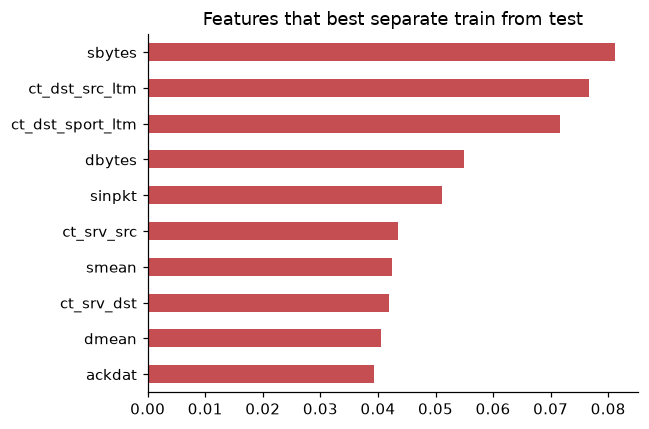

In [ ]:
n = min(len(X_train), len(X_test), 30000)
Xa = pd.concat([X_train[Num_Cols].sample(n, Random_State=Random_State),
                X_test[Num_Cols].sample(n, Random_State=Random_State)], ignore_index=True)
ya = np.r_[np.zeros(n), np.ones(n)]

adv = RandomForestClassifier(n_estimators=100, max_depth=12, n_jobs=1, Random_State=Random_State)
proba = cross_val_predict(adv, Xa, ya, cv=StratifiedKFold(5, shuffle=True, Random_State=Random_State),
                          method="predict_proba")[:, 1]
print(f"Adversarial validation AUC: {roc_auc_score(ya, proba):.3f}   (0.5 = indistinguishable)")

adv.fit(Xa, ya)
(pd.Series(adv.feature_importances_, index=Num_Cols).sort_values().tail(10)
   .plot.barh(figsize=(6, 4), color="#C44E52", title="Features that best separate train from test"))
plt.tight_layout(); plt.show()

Interpretation guide: the features at the top are the ones whose distribution differs most between the partitions. Compare them with the permutation-importance chart above; features that are both highly important to the model and highly different across partitions are the most likely cause of the drop.

## 10. Limitations and next steps

- **Official split, single run.** Scores come from one train/test pair with no confidence intervals. Small classes (Worms, Backdoor, Analysis) are noisy.
- **Distribution shift is real.** Class mix and feature distributions differ between the partitions (section 9). Scores here are lower than a random split, and closer to what a deployed detector would see.
- **Model selection on the test set.** The "best" model is chosen using test macro-F1. Use cross-validation on the training set for selection in future work.
- **No hyperparameter search.** Models use near-default settings. A cross-validated search scored on macro-F1 is an easy improvement.
- **False alarms.** Tune the decision threshold to an acceptable false-alarm rate instead of using 0.5.
- **Rare classes.** Options: resampling inside the CV loop, cost-sensitive learning, or a two-stage model (attack vs normal, then attack type).
- **Dataset artifacts.** Features such as `sttl` and `service` may encode the simulated testbed rather than generalisable attack behaviour. An ablation without them would test this.
- **Flow-level features only.** There is no temporal or payload information.